# Ocular Disease Dataset — EfficientNet-Lite2

Five-class fundus image classification using the curated Ocular Disease Dataset.

**Classes:** A (AMD), C (Cataract), D (Diabetic Retinopathy), G (Glaucoma), N (Normal).

**Model:** ImageNet-pretrained EfficientNet-Lite2 with a 5-class classifier.

**Setup:** 60/20/20 stratified split, 260x260 input, batch size 32, Focal Loss, AdamW, and two-GPU DataParallel when available.


## 1. Import Required Libraries

In [1]:
## 1. Import Required Libraries

import os
import sys
import shutil
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    auc
)

RANDOM_STATE=42

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Reproducibility and Device Configuration

In [2]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"]=str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic=True
        torch.backends.cudnn.benchmark=False

seed_everything(RANDOM_STATE)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
print(f"Number of GPUs: {torch.cuda.device_count()}")
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")


Using device: cuda
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Locate the Ocular Disease Dataset

In [3]:
required_classes=["A","C","D","G","N"]
dataset_root=None
for root in Path("/kaggle/input").rglob("*"):
    if root.is_dir() and all((root/x).is_dir() for x in required_classes):
        dataset_root=root
        break
if dataset_root is None:
    raise FileNotFoundError("Could not locate the Ocular Disease Dataset in /kaggle/input.")
print(f"Dataset path: {dataset_root}")


Dataset path: /kaggle/input/datasets/manan1717/ocular-disease-dataset/preprocessed


## 4. Define Class Mapping

In [4]:
class_mapping={
    "A":"Age-related Macular Degeneration",
    "C":"Cataract",
    "D":"Diabetic Retinopathy",
    "G":"Glaucoma",
    "N":"Normal"
}
class_names=list(class_mapping.values())
class_to_id={name:i for i,name in enumerate(class_names)}
print(f"Number of classes: {len(class_names)}")
for i,name in enumerate(class_names):
    print(f"  [{i}] {name}")


Number of classes: 5
  [0] Age-related Macular Degeneration
  [1] Cataract
  [2] Diabetic Retinopathy
  [3] Glaucoma
  [4] Normal


## 5. Build Image Metadata

In [5]:
records=[]
valid_extensions={".jpg",".jpeg",".png"}
for code_name,class_name in class_mapping.items():
    for path in (dataset_root/code_name).iterdir():
        if path.is_file() and path.suffix.lower() in valid_extensions:
            records.append({"filename":path.name,"image_path":str(path),"class_code":code_name,"class_name":class_name,"class_id":class_to_id[class_name]})
df=pd.DataFrame(records)
print(f"Total images found: {len(df)}")
display(df.head())


Total images found: 9290


,filename,image_path,class_code,class_name,class_id
0,0_RFiMD_55_ARMD.png,/kaggle/input/datasets/manan1717/ocular-diseas...,A,Age-related Macular Degeneration,0
1,0_ORID19_128_ARMD.png,/kaggle/input/datasets/manan1717/ocular-diseas...,A,Age-related Macular Degeneration,0
2,0_1kIM_4_ARMD.png,/kaggle/input/datasets/manan1717/ocular-diseas...,A,Age-related Macular Degeneration,0
3,0_ORID19_211_ARMD.png,/kaggle/input/datasets/manan1717/ocular-diseas...,A,Age-related Macular Degeneration,0
4,0_ORID19_100_ARMD.png,/kaggle/input/datasets/manan1717/ocular-diseas...,A,Age-related Macular Degeneration,0


## 6. Class Distribution

,Image Count
class_name,
Age-related Macular Degeneration,511
Cataract,1008
Diabetic Retinopathy,3128
Glaucoma,1646
Normal,2997


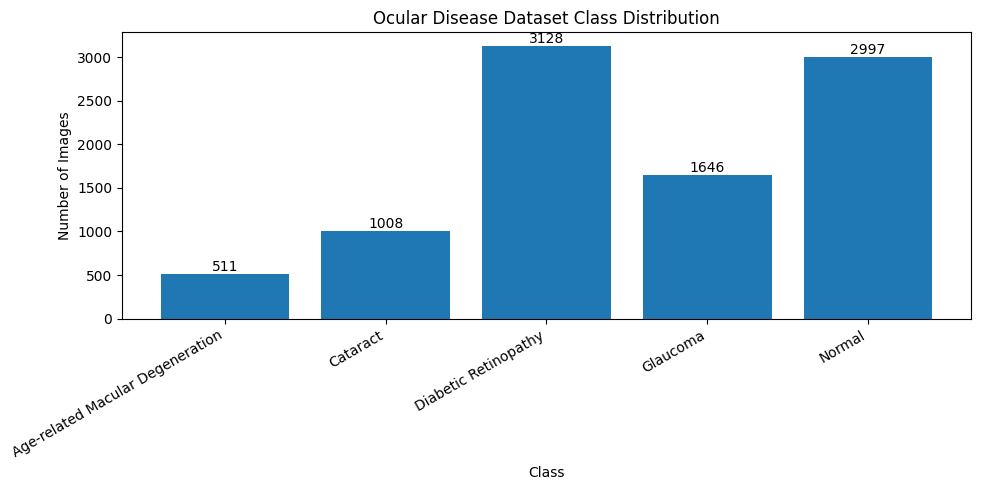

In [6]:
class_distribution=df["class_name"].value_counts().reindex(class_names)
display(class_distribution.to_frame("Image Count"))
plt.figure(figsize=(10,5))
bars=plt.bar(class_distribution.index,class_distribution.values)
plt.title("Ocular Disease Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30,ha="right")
for bar,value in zip(bars,class_distribution.values):
    plt.text(bar.get_x()+bar.get_width()/2,bar.get_height(),str(value),ha="center",va="bottom")
plt.tight_layout()
plt.show()


## 7. Validate Image Files

In [7]:
valid=[]
invalid=[]
for _,row in df.iterrows():
    try:
        with Image.open(row["image_path"]) as image: image.verify()
        valid.append(True)
    except Exception:
        valid.append(False); invalid.append(row["image_path"])
df["image_valid"]=valid
print(f"Valid images: {df['image_valid'].sum()}")
print(f"Invalid images: {(~df['image_valid']).sum()}")
df=df[df["image_valid"]].copy().reset_index(drop=True)


Valid images: 9290
Invalid images: 0


## 8. Stratified Train / Validation / Test Split

In [8]:
train_val_df,test_df=train_test_split(df,test_size=0.20,stratify=df["class_id"],random_state=RANDOM_STATE)
train_df,val_df=train_test_split(train_val_df,test_size=0.25,stratify=train_val_df["class_id"],random_state=RANDOM_STATE)
train_df=train_df.reset_index(drop=True)
val_df=val_df.reset_index(drop=True)
test_df=test_df.reset_index(drop=True)
print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test: {len(test_df)}")


Train: 5574
Validation: 1858
Test: 1858


## 9. Verify Split Distributions and No Overlap

In [9]:
split_distribution=pd.DataFrame({"Train":train_df["class_name"].value_counts(),"Validation":val_df["class_name"].value_counts(),"Test":test_df["class_name"].value_counts()}).reindex(class_names)
display(split_distribution)
train_paths=set(train_df["image_path"]); val_paths=set(val_df["image_path"]); test_paths=set(test_df["image_path"])
print(f"Train ∩ Validation: {len(train_paths & val_paths)}")
print(f"Train ∩ Test: {len(train_paths & test_paths)}")
print(f"Validation ∩ Test: {len(val_paths & test_paths)}")
assert not (train_paths & val_paths or train_paths & test_paths or val_paths & test_paths)


,Train,Validation,Test
class_name,,,
Age-related Macular Degeneration,307,102,102
Cataract,605,201,202
Diabetic Retinopathy,1876,626,626
Glaucoma,988,329,329
Normal,1798,600,599


Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


## 10. Training Class Weights

In [10]:
classes=np.array(sorted(train_df["class_id"].unique()))
weights=compute_class_weight(class_weight="balanced",classes=classes,y=train_df["class_id"])
class_weight_table=pd.DataFrame({"class_id":classes,"class_name":[class_names[i] for i in classes],"training_count":[int((train_df["class_id"]==i).sum()) for i in classes],"class_weight":np.round(weights,4)})
display(class_weight_table)


,class_id,class_name,training_count,class_weight
0,0,Age-related Macular Degeneration,307,3.6313
1,1,Cataract,605,1.8426
2,2,Diabetic Retinopathy,1876,0.5942
3,3,Glaucoma,988,1.1283
4,4,Normal,1798,0.6200


## 11. Dataset and Image Transforms

In [11]:
## 11. Preprocess and Save Images

IMG_SIZE=260

IMAGENET_MEAN=[0.485,0.456,0.406]
IMAGENET_STD=[0.229,0.224,0.225]

PREPROCESSED_ROOT="/kaggle/working/ocular_preprocessed"


def extract_retinal_fov(image):
    # Mid-level vision: Otsu thresholding + morphology to isolate the circular retinal field of view (FOV)
    gray=cv2.cvtColor(image,cv2.COLOR_RGB2GRAY)

    # 1. Gaussian blur suppresses sensor noise so the Otsu histogram is cleaner
    blurred=cv2.GaussianBlur(gray,(5,5),0)

    # 2. Otsu's method picks the global threshold automatically (fundus vs. black camera border)
    _,binary_mask=cv2.threshold(blurred,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)

    # 3. Opening removes isolated bright specks in the border, closing fills holes and rim gaps inside the FOV
    open_kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(5,5))
    close_kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(9,9))
    mask=cv2.morphologyEx(binary_mask,cv2.MORPH_OPEN,open_kernel)
    mask=cv2.morphologyEx(mask,cv2.MORPH_CLOSE,close_kernel)

    # 4. Bounding box of the cleaned foreground (fall back to the full image if segmentation fails)
    coords=np.column_stack(np.where(mask>0))

    if len(coords)==0 or (mask>0).mean()<0.05:
        return image,mask

    y_min,x_min=coords.min(axis=0)
    y_max,x_max=coords.max(axis=0)

    height=y_max-y_min+1
    width=x_max-x_min+1

    margin=int(0.02*max(height,width))

    y_min=max(0,y_min-margin)
    x_min=max(0,x_min-margin)
    y_max=min(image.shape[0],y_max+margin)
    x_max=min(image.shape[1],x_max+margin)

    return image[y_min:y_max,x_min:x_max],mask


def preprocess_image(image_path):

    image=cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Could not read image: {image_path}")

    image=cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

    # --------------------------------------------------------
    # 1. Detect retinal region (Otsu + morphology)
    # --------------------------------------------------------

    image,_=extract_retinal_fov(image)

    # --------------------------------------------------------
    # 2. Apply CLAHE
    # --------------------------------------------------------

    lab=cv2.cvtColor(image,cv2.COLOR_RGB2LAB)

    l_channel,a_channel,b_channel=cv2.split(lab)

    clahe=cv2.createCLAHE(clipLimit=2.0,tileGridSize=(8,8))

    l_channel=clahe.apply(l_channel)

    lab=cv2.merge([l_channel,a_channel,b_channel])

    image=cv2.cvtColor(lab,cv2.COLOR_LAB2RGB)

    # --------------------------------------------------------
    # 3. Resize to EfficientNet-Lite2 input size
    # --------------------------------------------------------

    image=cv2.resize(image,(IMG_SIZE,IMG_SIZE),interpolation=cv2.INTER_AREA)

    return image


def preprocess_split(df,split_name):

    output_root=Path(PREPROCESSED_ROOT)/split_name

    output_root.mkdir(parents=True,exist_ok=True)

    processed_df=df.copy().reset_index(drop=True)

    processed_paths=[]

    print(f"\nProcessing {split_name} images...")
    print(f"Number of images: {len(processed_df)}")

    for index,row in processed_df.iterrows():

        image=preprocess_image(row["image_path"])

        class_code=row["class_code"]

        class_dir=output_root/class_code

        class_dir.mkdir(parents=True,exist_ok=True)

        output_name=f"{index:06d}.jpg"

        output_path=class_dir/output_name

        image_bgr=cv2.cvtColor(image,cv2.COLOR_RGB2BGR)

        cv2.imwrite(str(output_path),image_bgr,[cv2.IMWRITE_JPEG_QUALITY,95])

        processed_paths.append(str(output_path))

        if (index+1)%500==0 or index==len(processed_df)-1:
            print(f"Processed {index+1}/{len(processed_df)}")

    processed_df["image_path"]=processed_paths

    return processed_df


# ------------------------------------------------------------
# Preprocess each split
# ------------------------------------------------------------

train_df_processed=preprocess_split(train_df,"train")

val_df_processed=preprocess_split(val_df,"validation")

test_df_processed=preprocess_split(test_df,"test")


print("\n"+"="*60)
print("PREPROCESSING COMPLETE")
print("="*60)

print(f"Training images:   {len(train_df_processed)}")
print(f"Validation images: {len(val_df_processed)}")
print(f"Test images:       {len(test_df_processed)}")

print(f"\nSaved to:")
print(PREPROCESSED_ROOT)


Processing train images...
Number of images: 5574
Processed 500/5574
Processed 1000/5574
Processed 1500/5574
Processed 2000/5574
Processed 2500/5574
Processed 3000/5574
Processed 3500/5574
Processed 4000/5574
Processed 4500/5574
Processed 5000/5574
Processed 5500/5574
Processed 5574/5574

Processing validation images...
Number of images: 1858
Processed 500/1858
Processed 1000/1858
Processed 1500/1858
Processed 1858/1858

Processing test images...
Number of images: 1858
Processed 500/1858
Processed 1000/1858
Processed 1500/1858
Processed 1858/1858

PREPROCESSING COMPLETE
Training images:   5574
Validation images: 1858
Test images:       1858

Saved to:
/kaggle/working/ocular_preprocessed


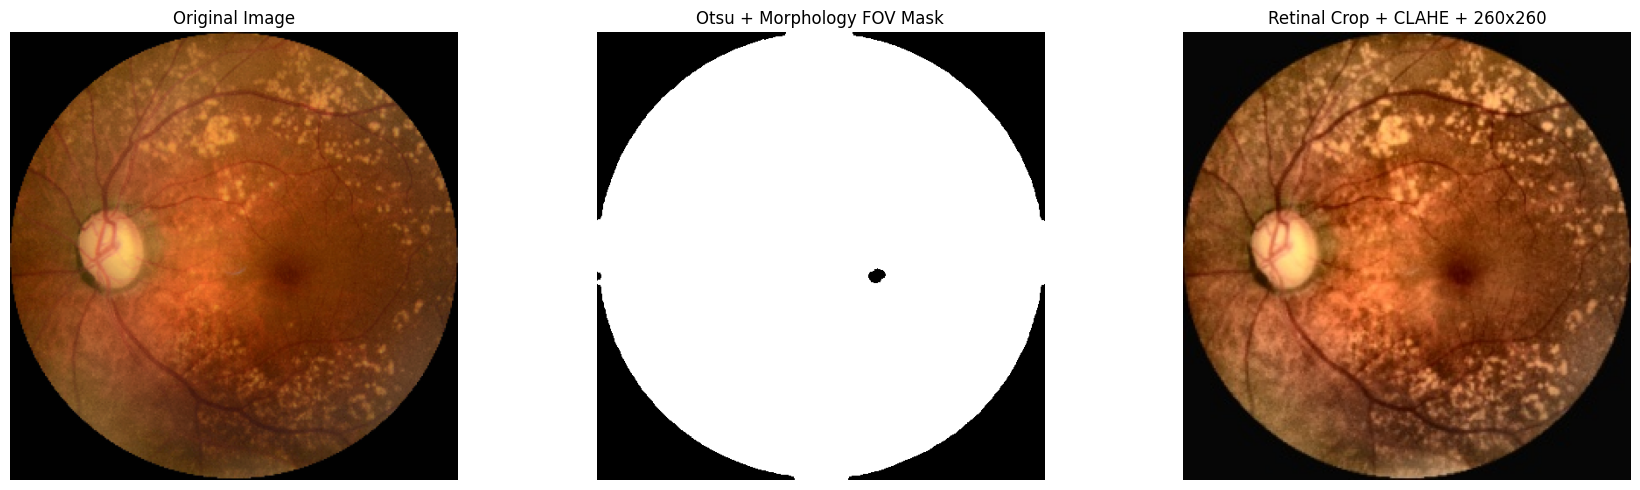

Processed image size: (260, 260)


In [12]:
## 11A. Verify Preprocessed Images (Otsu FOV Mask + Crop + CLAHE)

sample_original=train_df.iloc[0]["image_path"]
sample_processed=train_df_processed.iloc[0]["image_path"]

original=Image.open(sample_original).convert("RGB")

processed=Image.open(sample_processed).convert("RGB")

_,sample_fov_mask=extract_retinal_fov(np.array(original))


plt.figure(figsize=(18,5))

plt.subplot(1,3,1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(sample_fov_mask,cmap="gray")
plt.title("Otsu + Morphology FOV Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(processed)
plt.title("Retinal Crop + CLAHE + 260x260")
plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Processed image size: {processed.size}")

## 11B. Gabor Filter Bank (Low-Level Vision: Directional Texture and Vessel Enhancement)

A bank of 2D Gabor filters at several orientations and scales is applied to the green channel of the preprocessed fundus image. The green channel gives the highest vessel-to-background contrast, so the filter bank highlights the vessel network and fine texture that are relevant to Diabetic Retinopathy. This section is a visual analysis of the classical technique and does not change the images fed to the network.

Gabor bank size: 16 filters (2 scales x 8 orientations)


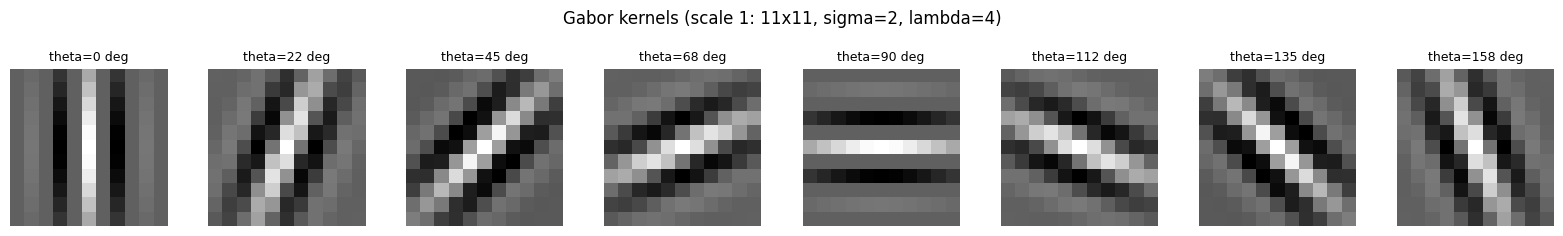

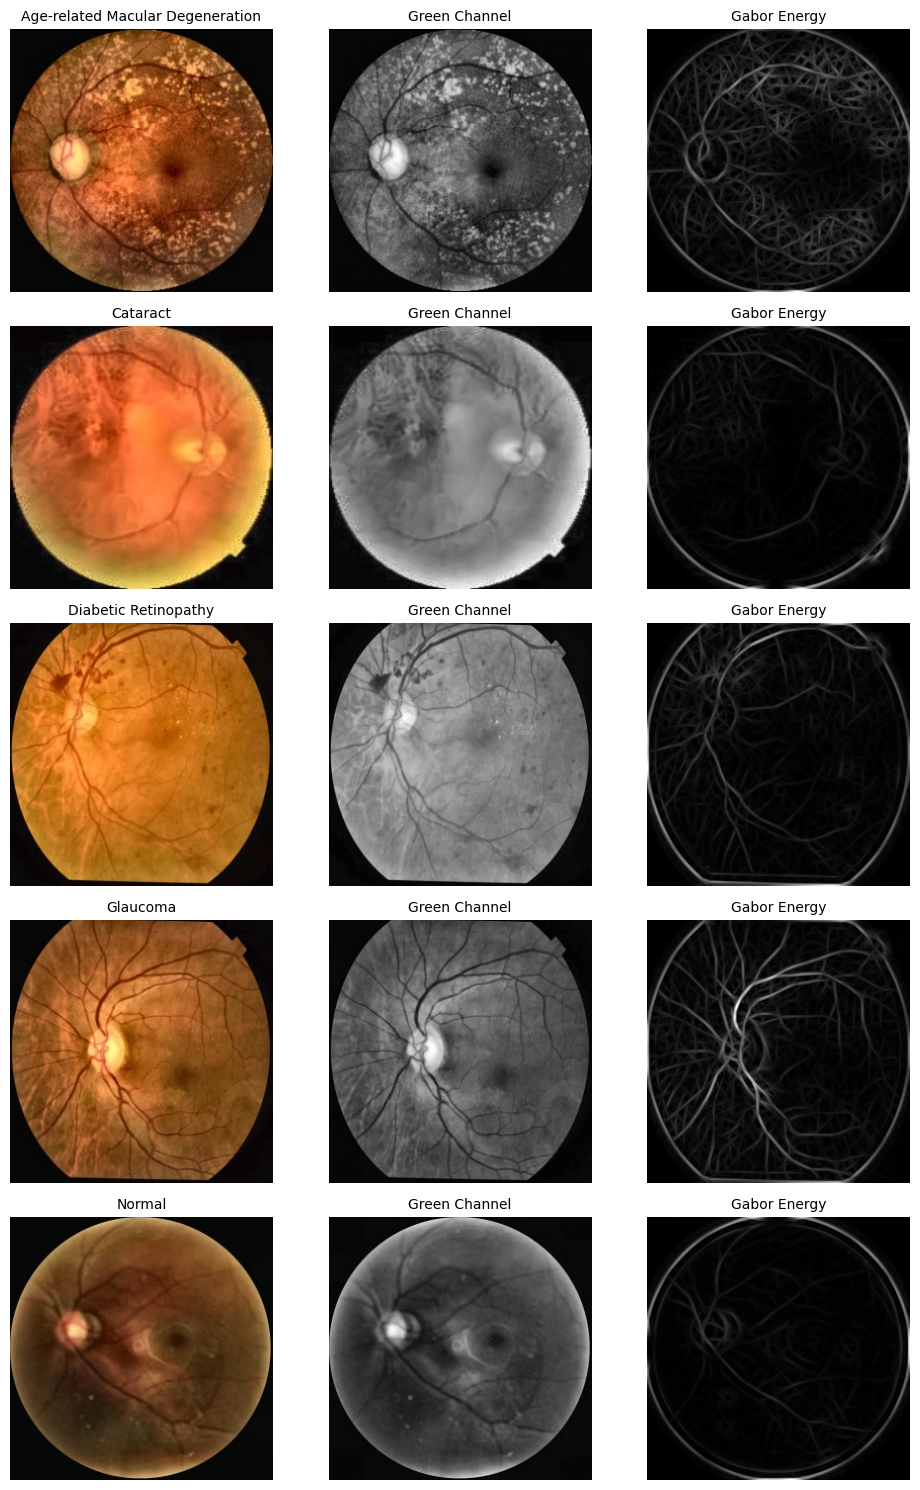

In [13]:
## 11B. Gabor Filter Bank

def build_gabor_bank(num_orientations=8,scales=((11,2.0,4.0),(21,4.0,8.0))):
    # Each scale is (kernel size, sigma, wavelength); orientations are evenly spaced over [0, pi)
    kernels=[]
    for ksize,sigma,lambd in scales:
        for i in range(num_orientations):
            theta=i*np.pi/num_orientations
            kernel=cv2.getGaborKernel((ksize,ksize),sigma,theta,lambd,0.5,0,ktype=cv2.CV_32F)
            kernel-=kernel.mean()
            kernels.append(((ksize,sigma,lambd,theta),kernel))
    return kernels


def apply_gabor_filter_bank(image_rgb,kernels):
    # Green channel is inverted so that dark vessels become bright ridges for the filter response
    green=255-image_rgb[:,:,1]
    green=green.astype(np.float32)
    responses=[cv2.filter2D(green,cv2.CV_32F,kernel) for _,kernel in kernels]
    energy=np.max(np.stack(responses,axis=0),axis=0)
    energy=np.clip(energy,0,None)
    return cv2.normalize(energy,None,0,255,cv2.NORM_MINMAX).astype(np.uint8)


gabor_kernels=build_gabor_bank()

print(f"Gabor bank size: {len(gabor_kernels)} filters (2 scales x 8 orientations)")

# Kernel visualisation for the first scale
plt.figure(figsize=(16,2.2))
for idx,((ksize,sigma,lambd,theta),kernel) in enumerate(gabor_kernels[:8]):
    plt.subplot(1,8,idx+1)
    plt.imshow(kernel,cmap="gray")
    plt.title(f"theta={np.degrees(theta):.0f} deg",fontsize=9)
    plt.axis("off")
plt.suptitle("Gabor kernels (scale 1: 11x11, sigma=2, lambda=4)",y=1.05)
plt.tight_layout()
plt.show()

# One sample per class: preprocessed image, green channel, Gabor energy map
sample_rows=train_df_processed.groupby("class_id").first().reset_index()

plt.figure(figsize=(10,3*len(sample_rows)))
for row_idx,row in sample_rows.iterrows():
    sample_rgb=np.array(Image.open(row["image_path"]).convert("RGB"))
    gabor_map=apply_gabor_filter_bank(sample_rgb,gabor_kernels)
    for col_idx,(im,title,cmap) in enumerate([(sample_rgb,row["class_name"],None),(sample_rgb[:,:,1],"Green Channel","gray"),(gabor_map,"Gabor Energy","gray")]):
        plt.subplot(len(sample_rows),3,row_idx*3+col_idx+1)
        plt.imshow(im,cmap=cmap)
        plt.title(title,fontsize=10)
        plt.axis("off")
plt.tight_layout()
plt.show()

In [14]:
## 11C. Training Transforms and Dataset

train_transforms=transforms.Compose([

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(degrees=15),

    transforms.ColorJitter(brightness=0.15,contrast=0.15,saturation=0.10),

    transforms.RandomAffine(degrees=0,translate=(0.05,0.05),scale=(0.95,1.05)),

    transforms.ToTensor(),

    transforms.Normalize(mean=IMAGENET_MEAN,std=IMAGENET_STD)
])


val_test_transforms=transforms.Compose([

    transforms.ToTensor(),

    transforms.Normalize(mean=IMAGENET_MEAN,std=IMAGENET_STD)
])


class OcularDiseaseDataset(Dataset):

    def __init__(self,df,transform=None):

        self.df=df.reset_index(drop=True)
        self.transform=transform

        self.image_paths=self.df["image_path"].values
        self.labels=self.df["class_id"].values

    def __len__(self):
        return len(self.df)

    def __getitem__(self,idx):

        image=Image.open(self.image_paths[idx]).convert("RGB")

        if self.transform is not None:
            image=self.transform(image)

        return image,torch.tensor(self.labels[idx],dtype=torch.long)


train_dataset=OcularDiseaseDataset(train_df_processed,train_transforms)

val_dataset=OcularDiseaseDataset(val_df_processed,val_test_transforms)

test_dataset=OcularDiseaseDataset(test_df_processed,val_test_transforms)


print(f"Input resolution: {IMG_SIZE}x{IMG_SIZE}")
print(f"Training images: {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")
print(f"Test images: {len(test_dataset)}")
print("Retinal cropping: Precomputed (Otsu + morphology)")
print("CLAHE: Precomputed")
print("Random augmentation: Training only")

Input resolution: 260x260
Training images: 5574
Validation images: 1858
Test images: 1858
Retinal cropping: Precomputed (Otsu + morphology)
CLAHE: Precomputed
Random augmentation: Training only


## 12. DataLoaders

In [15]:
## 12. DataLoaders

BATCH_SIZE=32
NUM_WORKERS=2
PIN_MEMORY=torch.cuda.is_available()

train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS,pin_memory=PIN_MEMORY,persistent_workers=True)

val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=PIN_MEMORY,persistent_workers=True)

test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=PIN_MEMORY,persistent_workers=True)

print("DataLoader Configuration:")
print(f"Batch size: {BATCH_SIZE}")
print(f"Num workers: {NUM_WORKERS}")
print(f"Train batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

DataLoader Configuration:
Batch size: 32
Num workers: 2
Train batches: 175
Validation batches: 59
Test batches: 59


## 13. Load EfficientNet-Lite2 Implementation and ImageNet Weights

In [16]:
MODEL_DIR=None
MODEL_FILE=None
WEIGHTS_PATH=None
for root,dirs,files in os.walk("/kaggle/input"):
    if "efficientnet_lite.py" in files and "efficientnet_lite2.pth" in files:
        MODEL_DIR=root; MODEL_FILE=os.path.join(root,"efficientnet_lite.py"); WEIGHTS_PATH=os.path.join(root,"efficientnet_lite2.pth"); break
if MODEL_DIR is None:
    raise FileNotFoundError("Could not find efficientnet_lite.py and efficientnet_lite2.pth in /kaggle/input.")
print(f"Model files found at: {MODEL_DIR}")
WORKING_MODEL_FILE="/kaggle/working/efficientnet_lite.py"
shutil.copy2(MODEL_FILE,WORKING_MODEL_FILE)
with open(WORKING_MODEL_FILE,"r",encoding="utf-8") as f: model_source=f.read()
model_source=model_source.replace("import torch.functional as F","import torch.nn.functional as F")
with open(WORKING_MODEL_FILE,"w",encoding="utf-8") as f: f.write(model_source)
if "/kaggle/working" not in sys.path: sys.path.insert(0,"/kaggle/working")
from efficientnet_lite import build_efficientnet_lite
model=build_efficientnet_lite("efficientnet_lite2",1000)
checkpoint=torch.load(WEIGHTS_PATH,map_location="cpu")
model.load_state_dict(checkpoint,strict=True)
in_features=model.fc.in_features
model.fc=nn.Linear(in_features,len(class_names))
model=model.to(device)
if torch.cuda.device_count()>1:
    print(f"Using {torch.cuda.device_count()} GPUs with DataParallel.")
    model=nn.DataParallel(model)
else:
    print("Using 1 GPU or CPU.")
total_params=sum(p.numel() for p in model.parameters())
trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Classifier: Linear({in_features},{len(class_names)})")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Model files found at: /kaggle/input/datasets/abhijithjayaniiitk/efficient-net-lite
Using 2 GPUs with DataParallel.
Classifier: Linear(1280,5)
Total parameters: 4,817,477
Trainable parameters: 4,817,477


## 14. Multiclass Focal Loss

In [17]:
class FocalLoss(nn.Module):
    def __init__(self,alpha=0.25,gamma=2.0,reduction="mean"):
        super().__init__(); self.alpha=alpha; self.gamma=gamma; self.reduction=reduction
    def forward(self,inputs,targets):
        log_p=F.log_softmax(inputs,dim=1); p=torch.exp(log_p)
        target_log_p=log_p.gather(1,targets.view(-1,1)).squeeze(1)
        target_p=p.gather(1,targets.view(-1,1)).squeeze(1)
        loss=-self.alpha*((1-target_p)**self.gamma)*target_log_p
        if self.reduction=="mean": return loss.mean()
        if self.reduction=="sum": return loss.sum()
        return loss

criterion=FocalLoss(alpha=0.25,gamma=2.0)
print("Loss: Multiclass Focal Loss")
print("Alpha: 0.25")
print("Gamma: 2.0")


Loss: Multiclass Focal Loss
Alpha: 0.25
Gamma: 2.0


## 15. Training Configuration

In [18]:
NUM_EPOCHS=30
LEARNING_RATE=1e-4
WEIGHT_DECAY=1e-4
PATIENCE=7
CHECKPOINT_PATH="/kaggle/working/best_efficientnet_lite2_ocular.pth"
optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="max",factor=0.5,patience=3)
print(f"Epochs: {NUM_EPOCHS}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Early stopping patience: {PATIENCE}")


Epochs: 30
Learning rate: 0.0001
Weight decay: 0.0001
Early stopping patience: 7


## 16. Sanity Check

In [19]:
images,labels=next(iter(train_loader))
images=images.to(device); labels=labels.to(device)
model.eval()
with torch.no_grad(): outputs=model(images); sanity_loss=criterion(outputs,labels)
print(f"Input shape: {images.shape}")
print(f"Output shape: {outputs.shape}")
print(f"Sanity loss: {sanity_loss.item():.4f}")
assert outputs.shape[1]==len(class_names)
assert torch.isfinite(sanity_loss)


Input shape: torch.Size([32, 3, 260, 260])
Output shape: torch.Size([32, 5])
Sanity loss: 0.2532


## 17. Training and Validation

In [20]:
## 17. Training and Validation

from tqdm.auto import tqdm


def run_epoch(model,loader,criterion,optimizer=None,phase="Train"):

    is_training=optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    running_loss=0.0
    all_preds=[]
    all_labels=[]

    progress_bar=tqdm(loader,desc=phase,leave=True)

    context=torch.enable_grad() if is_training else torch.no_grad()

    with context:

        for images,labels in progress_bar:

            images=images.to(device,non_blocking=True)

            labels=labels.to(device,non_blocking=True)

            if is_training:
                optimizer.zero_grad()

            outputs=model(images)

            loss=criterion(outputs,labels)

            if is_training:

                loss.backward()
                optimizer.step()

            running_loss+=loss.item()*images.size(0)

            preds=torch.argmax(outputs,dim=1)

            all_preds.extend(preds.detach().cpu().numpy())

            all_labels.extend(labels.detach().cpu().numpy())

            # Update progress bar
            current_loss=running_loss/len(all_labels)
            current_acc=accuracy_score(all_labels,all_preds)

            progress_bar.set_postfix(loss=f"{current_loss:.4f}",acc=f"{current_acc:.4f}")

    epoch_loss=running_loss/len(loader.dataset)

    epoch_acc=accuracy_score(all_labels,all_preds)

    epoch_precision=precision_score(all_labels,all_preds,average="macro",zero_division=0)

    epoch_recall=recall_score(all_labels,all_preds,average="macro",zero_division=0)

    epoch_f1=f1_score(all_labels,all_preds,average="macro",zero_division=0)

    return (epoch_loss,epoch_acc,epoch_precision,epoch_recall,epoch_f1)


history={"epoch":[],"train_loss":[],"train_acc":[],"val_loss":[],"val_acc":[],"val_precision":[],"val_recall":[],"val_f1":[]}


best_val_f1=-np.inf
best_epoch=0
patience_counter=0


print("Starting training...")
print("="*80)


for epoch in range(1,NUM_EPOCHS+1):

    start_time=time.time()

    print(f"\nEpoch {epoch:02d}/{NUM_EPOCHS}")

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    train_loss,train_acc,_,_,_=run_epoch(model,train_loader,criterion,optimizer,phase="Training")

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    val_loss,val_acc,val_precision,val_recall,val_f1=run_epoch(model,val_loader,criterion,phase="Validation")

    scheduler.step(val_f1)

    # --------------------------------------------------------
    # Store history
    # --------------------------------------------------------

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_precision"].append(val_precision)
    history["val_recall"].append(val_recall)
    history["val_f1"].append(val_f1)

    epoch_time=time.time()-start_time

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val Macro F1: {val_f1:.4f} | Time: {epoch_time:.1f}s")

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------

    if val_f1>best_val_f1:

        best_val_f1=val_f1
        best_epoch=epoch
        patience_counter=0

        state_dict=model.module.state_dict() if isinstance(model,nn.DataParallel) else model.state_dict()

        torch.save({"epoch":epoch,"model_state_dict":state_dict,"optimizer_state_dict":optimizer.state_dict(),"scheduler_state_dict":scheduler.state_dict(),"val_f1":best_val_f1},CHECKPOINT_PATH)

        print(f"  Best model saved. Val Macro F1: {best_val_f1:.4f}")
    else:
        patience_counter+=1
        print(f"  No improvement. Patience: {patience_counter}/{PATIENCE}")

        if patience_counter>=PATIENCE:

            print("Early stopping triggered.")

            break


print("="*80)
print(f"Best epoch: {best_epoch}")
print(f"Best validation Macro F1: {best_val_f1:.4f}")

Starting training...

Epoch 01/30


Training:   0%|          | 0/175 [00:00<?, ?it/s]

Validation:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 01/30 | Train Loss: 0.1369 | Train Acc: 0.5850 | Val Loss: 0.0720 | Val Acc: 0.7470 | Val Macro F1: 0.6885 | Time: 37.2s
  Best model saved. Val Macro F1: 0.6885

Epoch 02/30


Training:   0%|          | 0/175 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 29/30 | Train Loss: 0.0199 | Train Acc: 0.8859 | Val Loss: 0.0305 | Val Acc: 0.8536 | Val Macro F1: 0.8984 | Time: 37.7s
  No improvement. Patience: 2/7

Epoch 30/30


Training:   0%|          | 0/175 [00:00<?, ?it/s]

Validation:   0%|          | 0/59 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss: 0.0188 | Train Acc: 0.8859 | Val Loss: 0.0312 | Val Acc: 0.8558 | Val Macro F1: 0.8988 | Time: 37.6s
  No improvement. Patience: 3/7
Best epoch: 27
Best validation Macro F1: 0.9001


## 18. Training Curves

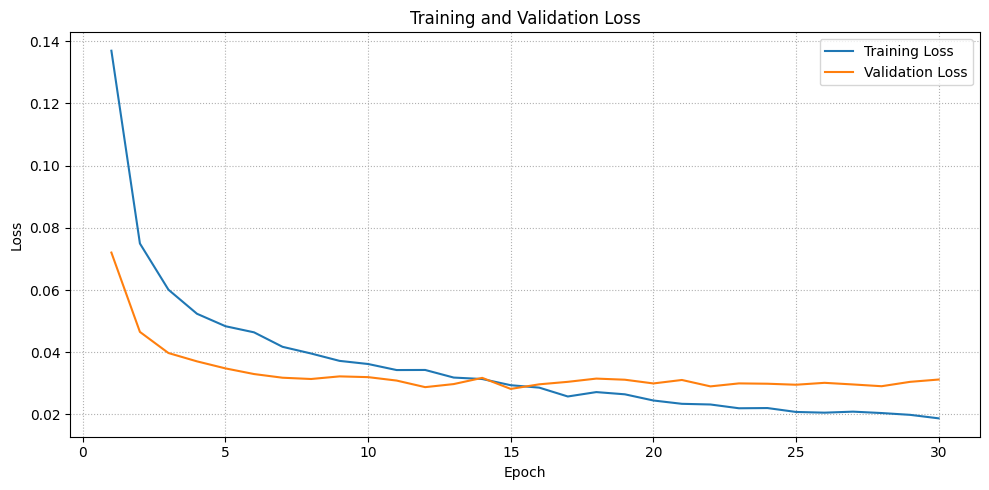

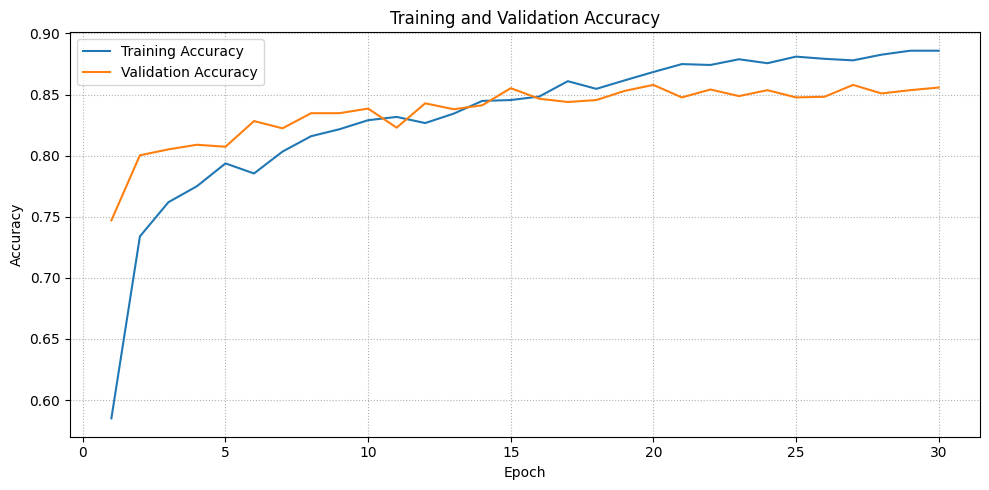

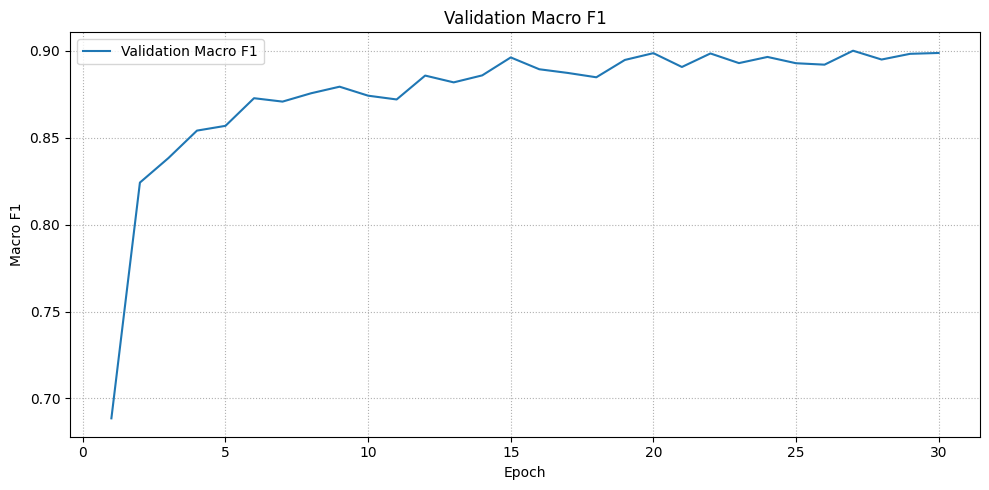

In [21]:
history_df=pd.DataFrame(history)
plt.figure(figsize=(10,5)); plt.plot(history_df["epoch"],history_df["train_loss"],label="Training Loss"); plt.plot(history_df["epoch"],history_df["val_loss"],label="Validation Loss"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Training and Validation Loss"); plt.legend(); plt.grid(True,linestyle=":"); plt.tight_layout(); plt.show()
plt.figure(figsize=(10,5)); plt.plot(history_df["epoch"],history_df["train_acc"],label="Training Accuracy"); plt.plot(history_df["epoch"],history_df["val_acc"],label="Validation Accuracy"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Training and Validation Accuracy"); plt.legend(); plt.grid(True,linestyle=":"); plt.tight_layout(); plt.show()
plt.figure(figsize=(10,5)); plt.plot(history_df["epoch"],history_df["val_f1"],label="Validation Macro F1"); plt.xlabel("Epoch"); plt.ylabel("Macro F1"); plt.title("Validation Macro F1"); plt.legend(); plt.grid(True,linestyle=":"); plt.tight_layout(); plt.show()


## 19. Final Test Evaluation

In [22]:
best_checkpoint=torch.load(CHECKPOINT_PATH,map_location=device)
target_model=model.module if isinstance(model,nn.DataParallel) else model
target_model.load_state_dict(best_checkpoint["model_state_dict"],strict=True)
print(f"Restored Epoch {best_checkpoint['epoch']} with Val Macro F1 {best_checkpoint['val_f1']:.4f}")
model.eval(); test_loss=0.0; test_preds=[]; test_labels=[]; test_probs=[]
with torch.no_grad():
    for images,labels in test_loader:
        images=images.to(device,non_blocking=True); labels=labels.to(device,non_blocking=True)
        outputs=model(images); loss=criterion(outputs,labels); test_loss+=loss.item()*images.size(0)
        test_probs.extend(F.softmax(outputs,dim=1).cpu().numpy()); test_preds.extend(torch.argmax(outputs,dim=1).cpu().numpy()); test_labels.extend(labels.cpu().numpy())
y_test_true=np.array(test_labels); y_test_pred=np.array(test_preds); y_test_probs=np.array(test_probs)
test_final_loss=test_loss/len(test_dataset)
test_accuracy=accuracy_score(y_test_true,y_test_pred)
test_macro_precision=precision_score(y_test_true,y_test_pred,average="macro",zero_division=0)
test_macro_recall=recall_score(y_test_true,y_test_pred,average="macro",zero_division=0)
test_macro_f1=f1_score(y_test_true,y_test_pred,average="macro",zero_division=0)
print("="*55); print("FINAL TEST EVALUATION METRICS"); print("="*55)
print(f"Test Loss:            {test_final_loss:.4f}")
print(f"Test Accuracy:        {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Test Macro Precision: {test_macro_precision:.4f}")
print(f"Test Macro Recall:    {test_macro_recall:.4f}")
print(f"Test Macro F1:        {test_macro_f1:.4f}")
print("="*55)


Restored Epoch 27 with Val Macro F1 0.9001
FINAL TEST EVALUATION METRICS
Test Loss:            0.0320
Test Accuracy:        0.8498 (84.98%)
Test Macro Precision: 0.8935
Test Macro Recall:    0.8901
Test Macro F1:        0.8901


## 20. Classification Report

In [23]:
print(classification_report(y_test_true,y_test_pred,target_names=class_names,digits=4,zero_division=0))


                                  precision    recall  f1-score   support

Age-related Macular Degeneration     0.9700    0.9510    0.9604       102
                        Cataract     0.9801    0.9752    0.9777       202
            Diabetic Retinopathy     0.8662    0.7444    0.8007       626
                        Glaucoma     0.8905    0.9149    0.9025       329
                          Normal     0.7606    0.8648    0.8094       599

                        accuracy                         0.8498      1858
                       macro avg     0.8935    0.8901    0.8901      1858
                    weighted avg     0.8546    0.8498    0.8495      1858



## 21. Confusion Matrix

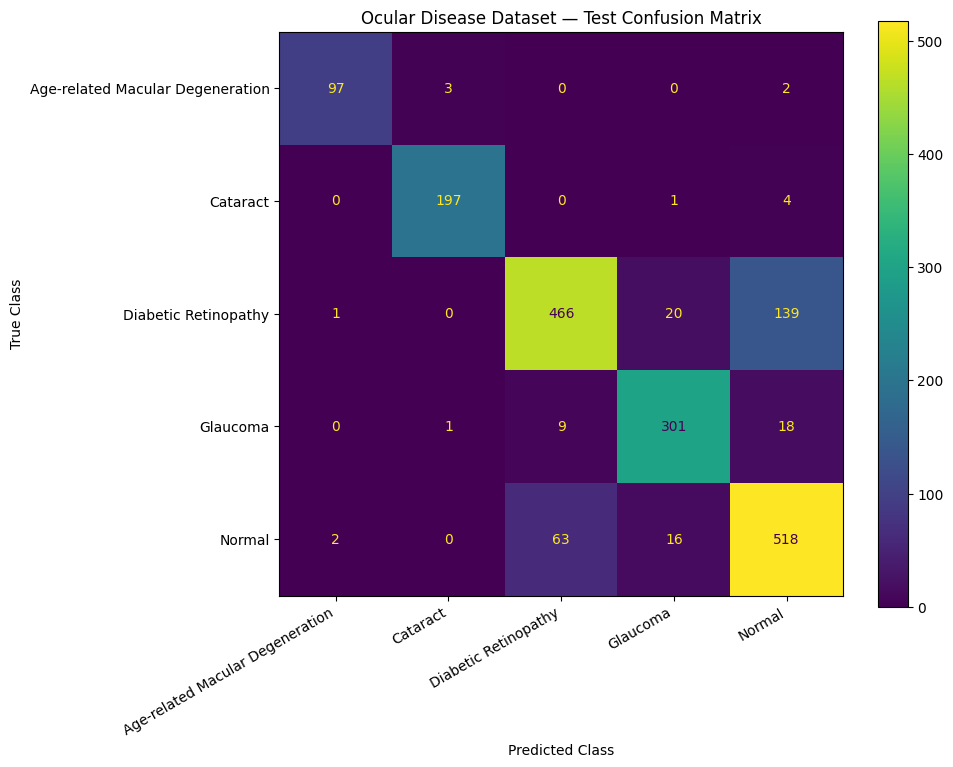

In [24]:
cm=confusion_matrix(y_test_true,y_test_pred)
plt.figure(figsize=(10,8)); disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names); disp.plot(values_format="d",ax=plt.gca(),colorbar=True); plt.title("Ocular Disease Dataset — Test Confusion Matrix"); plt.xlabel("Predicted Class"); plt.ylabel("True Class"); plt.xticks(rotation=30,ha="right"); plt.tight_layout(); plt.show()


## 22. Multiclass ROC-AUC

Macro ROC-AUC: 0.9732
Weighted ROC-AUC: 0.9577


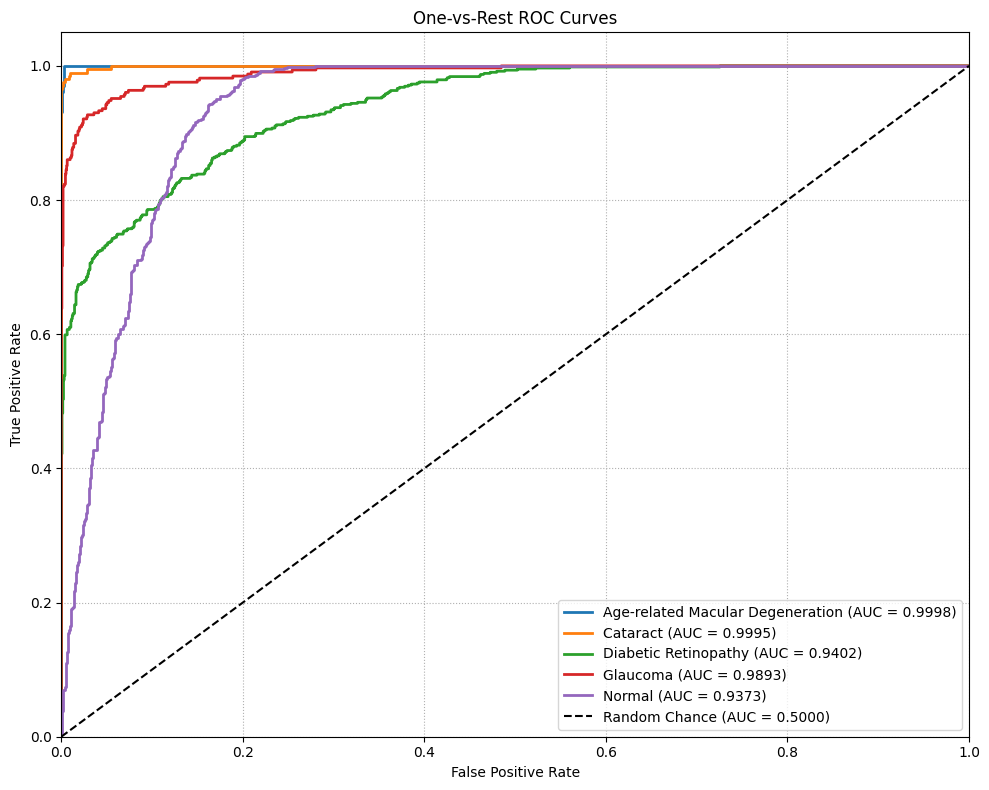

In [25]:
num_classes=len(class_names); y_test_one_hot=np.eye(num_classes)[y_test_true]
try:
    test_macro_roc_auc=roc_auc_score(y_test_one_hot,y_test_probs,multi_class="ovr",average="macro")
    test_weighted_roc_auc=roc_auc_score(y_test_one_hot,y_test_probs,multi_class="ovr",average="weighted")
except Exception as e:
    print(f"ROC-AUC calculation note: {e}"); test_macro_roc_auc=np.nan; test_weighted_roc_auc=np.nan
print(f"Macro ROC-AUC: {test_macro_roc_auc:.4f}")
print(f"Weighted ROC-AUC: {test_weighted_roc_auc:.4f}")
plt.figure(figsize=(10,8))
for i in range(num_classes):
    if np.sum(y_test_one_hot[:,i])>0:
        fpr,tpr,_=roc_curve(y_test_one_hot[:,i],y_test_probs[:,i]); class_auc=auc(fpr,tpr); plt.plot(fpr,tpr,linewidth=2,label=f"{class_names[i]} (AUC = {class_auc:.4f})")
plt.plot([0,1],[0,1],"k--",label="Random Chance (AUC = 0.5000)"); plt.xlim([0,1]); plt.ylim([0,1.05]); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("One-vs-Rest ROC Curves"); plt.legend(loc="lower right"); plt.grid(True,linestyle=":"); plt.tight_layout(); plt.show()


## 23. Sample Predictions

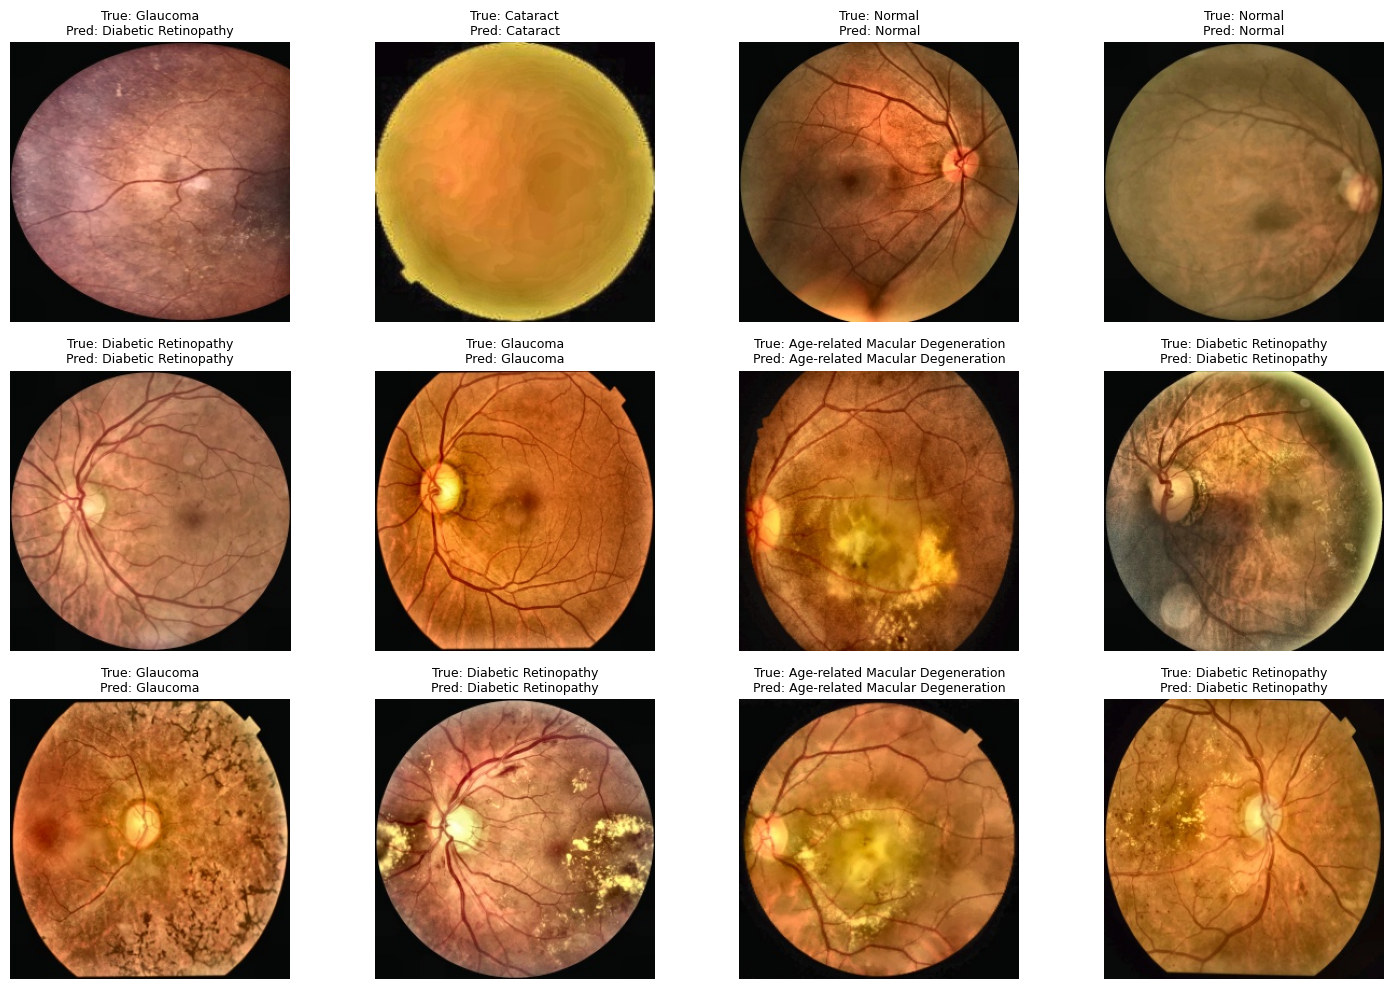

In [26]:
model.eval(); sample_images,sample_labels=next(iter(test_loader)); sample_device=sample_images.to(device)
with torch.no_grad(): sample_outputs=model(sample_device); sample_preds=torch.argmax(sample_outputs,dim=1).cpu().numpy()
plt.figure(figsize=(15,10))
for i in range(min(12,len(sample_images))):
    image=sample_images[i].permute(1,2,0).numpy(); image=np.clip(image*np.array(IMAGENET_STD)+np.array(IMAGENET_MEAN),0,1)
    plt.subplot(3,4,i+1); plt.imshow(image); plt.axis("off"); plt.title(f"True: {class_names[sample_labels[i]]}\nPred: {class_names[sample_preds[i]]}",fontsize=9)
plt.tight_layout(); plt.show()


## 24. Misclassification Analysis

In [27]:
misclassified=np.where(y_test_true!=y_test_pred)[0]
print(f"Test images: {len(y_test_true)}")
print(f"Correct predictions: {np.sum(y_test_true==y_test_pred)}")
print(f"Misclassified images: {len(misclassified)}")
print("\nMost common misclassification pairs:")
pairs=pd.Series([(class_names[y_test_true[i]],class_names[y_test_pred[i]]) for i in misclassified]).value_counts()
for (true_class,pred_class),count in pairs.head(15).items(): print(f"{true_class} -> {pred_class}: {count}")


Test images: 1858
Correct predictions: 1579
Misclassified images: 279

Most common misclassification pairs:
Diabetic Retinopathy -> Normal: 139
Normal -> Diabetic Retinopathy: 63
Diabetic Retinopathy -> Glaucoma: 20
Glaucoma -> Normal: 18
Normal -> Glaucoma: 16
Glaucoma -> Diabetic Retinopathy: 9
Cataract -> Normal: 4
Age-related Macular Degeneration -> Cataract: 3
Age-related Macular Degeneration -> Normal: 2
Normal -> Age-related Macular Degeneration: 2
Diabetic Retinopathy -> Age-related Macular Degeneration: 1
Cataract -> Glaucoma: 1
Glaucoma -> Cataract: 1


Confusion Matrix:
[[ 97   3   0   0   2]
 [  0 197   0   1   4]
 [  1   0 466  20 139]
 [  0   1   9 301  18]
 [  2   0  63  16 518]]


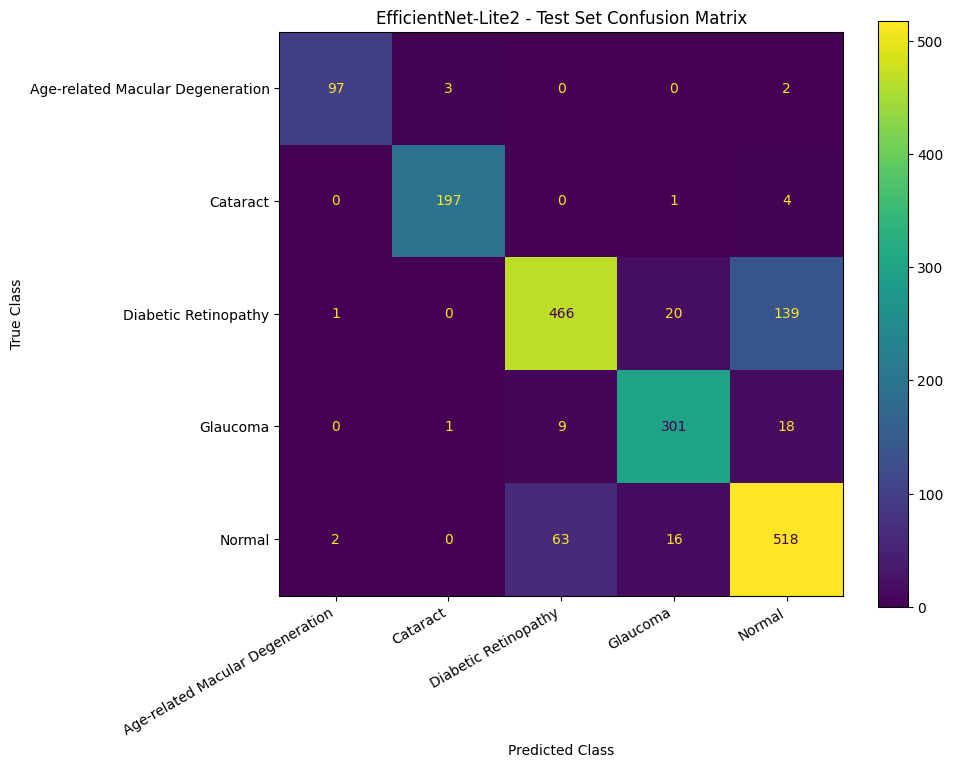

In [28]:
## 25. Confusion Matrix

cm=confusion_matrix(y_test_true,y_test_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(10,8))

disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)

disp.plot(values_format="d",ax=plt.gca(),colorbar=True)

plt.title("EfficientNet-Lite2 - Test Set Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.xticks(rotation=30,ha="right")
plt.tight_layout()
plt.show()

## 25. Per-Class Test Metrics

In [29]:
report=classification_report(y_test_true,y_test_pred,target_names=class_names,output_dict=True,zero_division=0)
per_class_metrics=pd.DataFrame({"Class":class_names,"Precision":[report[x]["precision"] for x in class_names],"Recall":[report[x]["recall"] for x in class_names],"F1":[report[x]["f1-score"] for x in class_names],"Support":[int(report[x]["support"]) for x in class_names]})
display(per_class_metrics)


,Class,Precision,Recall,F1,Support
0,Age-related Macular Degeneration,0.970000,0.950980,0.960396,102
1,Cataract,0.980100,0.975248,0.977667,202
2,Diabetic Retinopathy,0.866171,0.744409,0.800687,626
3,Glaucoma,0.890533,0.914894,0.902549,329
4,Normal,0.760646,0.864775,0.809375,599


## 26. Final Results Summary

In [30]:
summary_metrics=[
    ("Dataset","Ocular Disease Dataset"),("Number of Classes",str(len(class_names))),
    ("Input Size",f"{IMG_SIZE}x{IMG_SIZE}"),("Model","EfficientNet-Lite2"),
    ("Parameters",f"{total_params:,}"),("Trainable Parameters",f"{trainable_params:,}"),
    ("Loss","Multiclass Focal Loss"),("Alpha","0.25"),("Gamma","2.0"),
    ("Optimizer","AdamW"),("Learning Rate",str(LEARNING_RATE)),("Weight Decay",str(WEIGHT_DECAY)),
    ("Batch Size",str(BATCH_SIZE)),("GPUs",str(torch.cuda.device_count())),("Best Epoch",str(best_epoch)),
    ("Best Validation Macro F1",f"{best_val_f1:.4f}"),("Test Accuracy",f"{test_accuracy:.4f}"),
    ("Test Macro Precision",f"{test_macro_precision:.4f}"),("Test Macro Recall",f"{test_macro_recall:.4f}"),
    ("Test Macro F1",f"{test_macro_f1:.4f}"),("Test Macro ROC-AUC",f"{test_macro_roc_auc:.4f}")
]
display(pd.DataFrame(summary_metrics,columns=["Metric","Value"]))


,Metric,Value
0,Dataset,Ocular Disease Dataset
1,Number of Classes,5
2,Input Size,260x260
3,Model,EfficientNet-Lite2
4,Parameters,"4,817,477"
5,Trainable Parameters,"4,817,477"
6,Loss,Multiclass Focal Loss
7,Alpha,0.25
8,Gamma,2.0
9,Optimizer,AdamW


## Experiment Notes

The best checkpoint is selected using validation Macro F1. The test set is evaluated only after model selection and is not used for training, early stopping, or hyperparameter selection.
